In [22]:
# Import pandas for data manipulation and analysis
import pandas as pd

# Import numpy for numerical operations
import numpy as np

# Import matplotlib for visualization
import matplotlib.pyplot as plt

# Import seaborn for statistical visualizations
import seaborn as sns

# Display plots directly inside the Jupyter Notebook
%matplotlib inline

# ADF test is used to check whether the time series is stationary
from statsmodels.tsa.stattools import adfuller

# ACF and PACF are used to determine initial ARIMA parameters
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ARIMA model implementation
from statsmodels.tsa.arima.model import ARIMA

# Statistical tests for residual diagnostics
from statsmodels.stats.diagnostic import acorr_ljungbox

# Used to create a normal Q-Q plot of residuals
import statsmodels.api as sm

# Metrics that will also be useful for evaluating the forecast
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Data Preparation and Exploration

In [2]:
# Load the exchange rate dataset
df = pd.read_csv("exchange_rate.csv")

# Display the first 5 rows to understand the structure of the dataset
df.head()

,date,Ex_rate
0,01-01-1990 00:00,0.7855
1,02-01-1990 00:00,0.7818
2,03-01-1990 00:00,0.7867
3,04-01-1990 00:00,0.7860
4,05-01-1990 00:00,0.7849


In [3]:
# Display the number of rows and columns
print("Shape of the dataset:", df.shape)

Shape of the dataset: (7588, 2)


In [4]:
# Display all column names
print("Columns in the dataset:")
print(df.columns)

Columns in the dataset:
Index(['date', 'Ex_rate'], dtype='object')


In [5]:
# Display the data type of each column
print(df.dtypes)

date        object
Ex_rate    float64
dtype: object


In [6]:
# Convert the 'date' column from object/string format to datetime format
df['date'] = pd.to_datetime(df['date'], dayfirst=True)

# Check the data types again after conversion
print(df.dtypes)

date       datetime64[ns]
Ex_rate           float64
dtype: object


In [7]:
# Display the earliest date in the dataset
print("Start date:", df['date'].min())

# Display the latest date in the dataset
print("End date:", df['date'].max())

Start date: 1990-01-01 00:00:00
End date: 2010-10-10 00:00:00


In [8]:
# Sort the observations chronologically using the date column
df = df.sort_values(by='date')

# Reset the DataFrame index after sorting
df = df.reset_index(drop=True)

# Display the first few rows
df.head()

,date,Ex_rate
0,1990-01-01,0.7855
1,1990-01-02,0.7818
2,1990-01-03,0.7867
3,1990-01-04,0.7860
4,1990-01-05,0.7849


In [9]:
# Make the date column the index of the DataFrame
# This is useful for time-series analysis and visualization
df.set_index('date', inplace=True)

# Display the first five observations
df.head()

,Ex_rate
date,
1990-01-01,0.7855
1990-01-02,0.7818
1990-01-03,0.7867
1990-01-04,0.7860
1990-01-05,0.7849


In [10]:
# Display summary statistics of the exchange-rate variable
print(df['Ex_rate'].describe())

count    7588.000000
mean        0.776974
std         0.136620
min         0.483297
25%         0.701422
50%         0.761377
75%         0.873477
max         1.102536
Name: Ex_rate, dtype: float64


In [11]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values)

Missing values:
Ex_rate    0
dtype: int64


In [12]:
# Check whether duplicate rows exist
duplicate_rows = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 2258


In [13]:
# Check whether any dates occur more than once
duplicate_dates = df.index.duplicated().sum()

print("Number of duplicate dates:", duplicate_dates)

Number of duplicate dates: 0


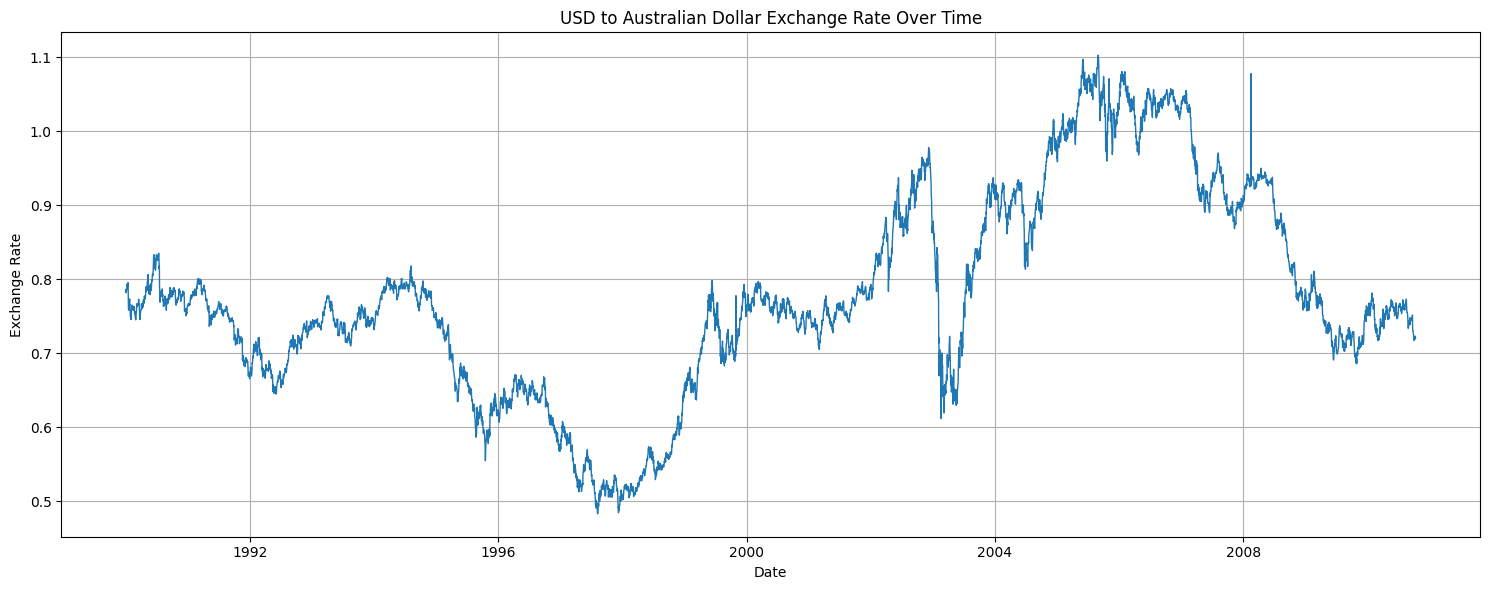

In [14]:
# Create a figure for the time-series plot
plt.figure(figsize=(15, 6))

# Plot exchange rate against date
plt.plot(df.index, df['Ex_rate'], linewidth=1)

# Add a title
plt.title('USD to Australian Dollar Exchange Rate Over Time')

# Label the x-axis
plt.xlabel('Date')

# Label the y-axis
plt.ylabel('Exchange Rate')

# Add grid lines to make the graph easier to read
plt.grid(True)

# Automatically adjust the layout
plt.tight_layout()

# Display the plot
plt.show()

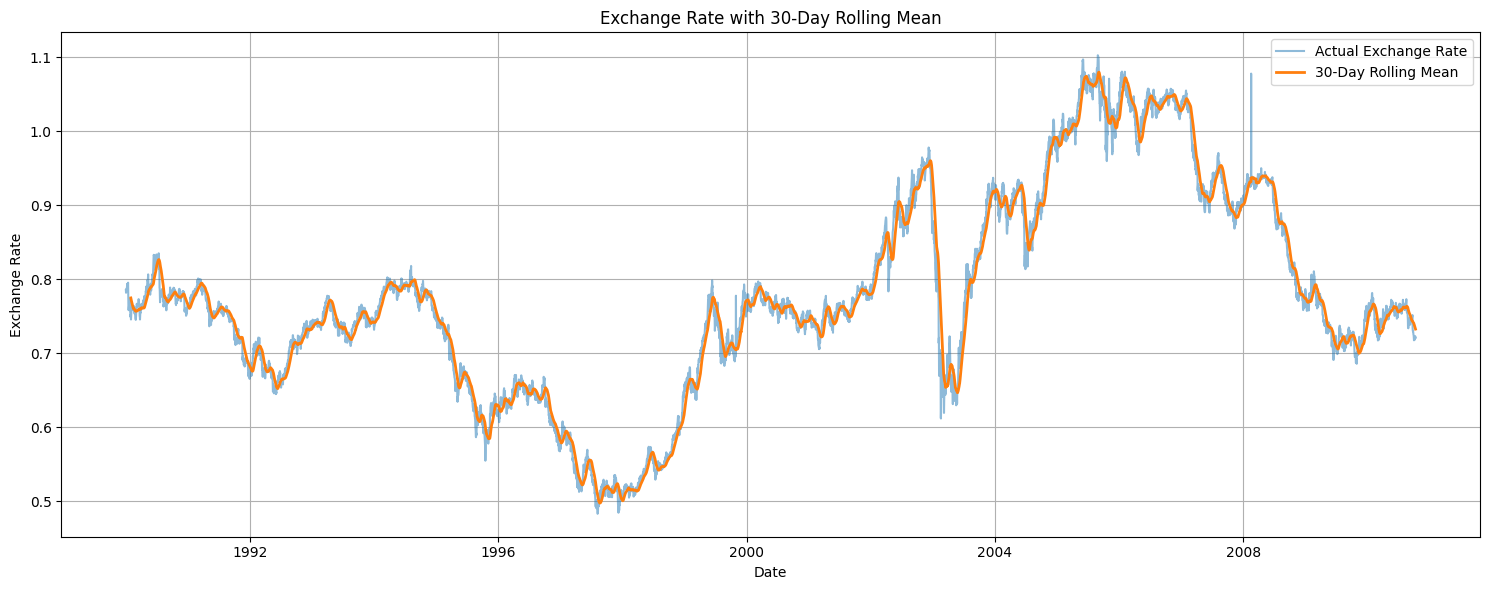

In [15]:
# Calculate a 30-day rolling average
df['rolling_mean_30'] = df['Ex_rate'].rolling(window=30).mean()

# Create the plot
plt.figure(figsize=(15, 6))

# Plot the original exchange rate
plt.plot(
    df.index,
    df['Ex_rate'],
    label='Actual Exchange Rate',
    alpha=0.5
)

# Plot the 30-day rolling average
plt.plot(
    df.index,
    df['rolling_mean_30'],
    label='30-Day Rolling Mean',
    linewidth=2
)

# Add title and labels
plt.title('Exchange Rate with 30-Day Rolling Mean')
plt.xlabel('Date')
plt.ylabel('Exchange Rate')

# Display legend
plt.legend()

# Add grid
plt.grid(True)

plt.tight_layout()
plt.show()

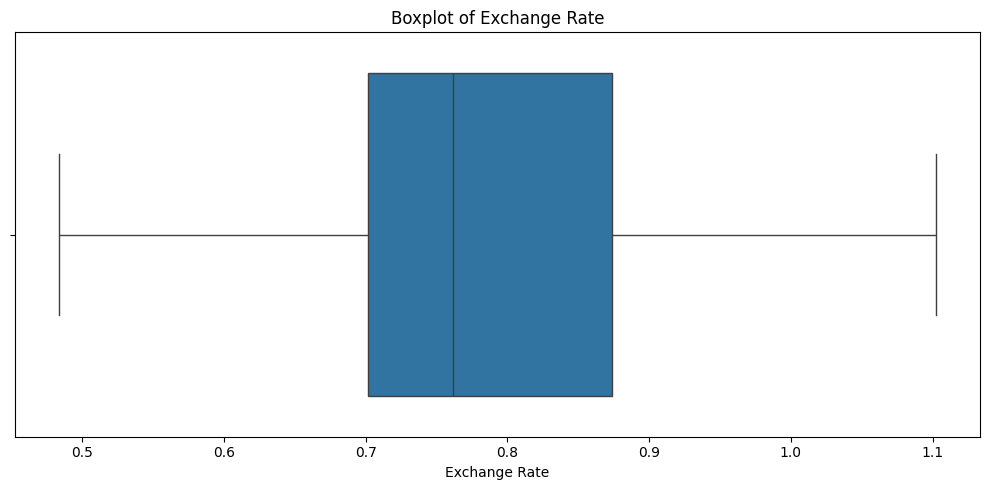

In [16]:
# Create a boxplot for the exchange rate
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['Ex_rate'])

# Add title
plt.title('Boxplot of Exchange Rate')

# Label the x-axis
plt.xlabel('Exchange Rate')

plt.tight_layout()
plt.show()

In [17]:
# Calculate the first quartile (Q1)
Q1 = df['Ex_rate'].quantile(0.25)

# Calculate the third quartile (Q3)
Q3 = df['Ex_rate'].quantile(0.75)

# Calculate the Interquartile Range
IQR = Q3 - Q1

# Calculate lower and upper boundaries for potential outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify observations outside the boundaries
outliers = df[
    (df['Ex_rate'] < lower_bound) |
    (df['Ex_rate'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("Number of potential outliers:", len(outliers))

Q1: 0.701422
Q3: 0.873477
IQR: 0.17205499999999996
Lower Bound: 0.44333950000000005
Upper Bound: 1.1315594999999998
Number of potential outliers: 0


In [18]:
# Create a complete daily date range from the minimum to maximum date
complete_dates = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq='D'
)

# Find dates that are present in the complete range but absent from the dataset
missing_dates = complete_dates.difference(df.index)

print("Number of missing dates:", len(missing_dates))

# Display the first 10 missing dates, if any
print(missing_dates[:10])

Number of missing dates: 0
DatetimeIndex([], dtype='datetime64[ns]', freq='D')


In [19]:
# Remove the rolling mean column because it was only used for visualization
df.drop(columns=['rolling_mean_30'], inplace=True)

# Verify the final dataset
print(df.head())

# Check for missing values one final time
print("\nFinal missing-value check:")
print(df.isnull().sum())

# Check the final shape
print("\nFinal dataset shape:", df.shape)

            Ex_rate
date               
1990-01-01   0.7855
1990-01-02   0.7818
1990-01-03   0.7867
1990-01-04   0.7860
1990-01-05   0.7849

Final missing-value check:
Ex_rate    0
dtype: int64

Final dataset shape: (7588, 1)


In [20]:
# Display information about the final preprocessed dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 7588 entries, 1990-01-01 to 2010-10-10
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Ex_rate  7588 non-null   float64
dtypes: float64(1)
memory usage: 376.6 KB


# Model Building - ARIMA

In [23]:
# Select only the exchange-rate column for ARIMA modeling
# We use .dropna() to make sure there are no missing observations
series = df['Ex_rate'].dropna()

# Display the first few observations
print(series.head())

# Display the total number of observations
print("\nNumber of observations:", len(series))

date
1990-01-01    0.7855
1990-01-02    0.7818
1990-01-03    0.7867
1990-01-04    0.7860
1990-01-05    0.7849
Name: Ex_rate, dtype: float64

Number of observations: 7588


In [24]:
# Perform the Augmented Dickey-Fuller test
adf_result = adfuller(series)

# Extract the test statistic
adf_statistic = adf_result[0]

# Extract the p-value
p_value = adf_result[1]

# Print the results
print("ADF Test Statistic:", adf_statistic)
print("ADF p-value:", p_value)

ADF Test Statistic: -1.6649941807381414
ADF p-value: 0.4492327353597959


In [25]:
# Interpret the ADF test result
if p_value < 0.05:
    print("\nThe series is stationary because p-value < 0.05.")
else:
    print("\nThe series is non-stationary because p-value >= 0.05.")


The series is non-stationary because p-value >= 0.05.


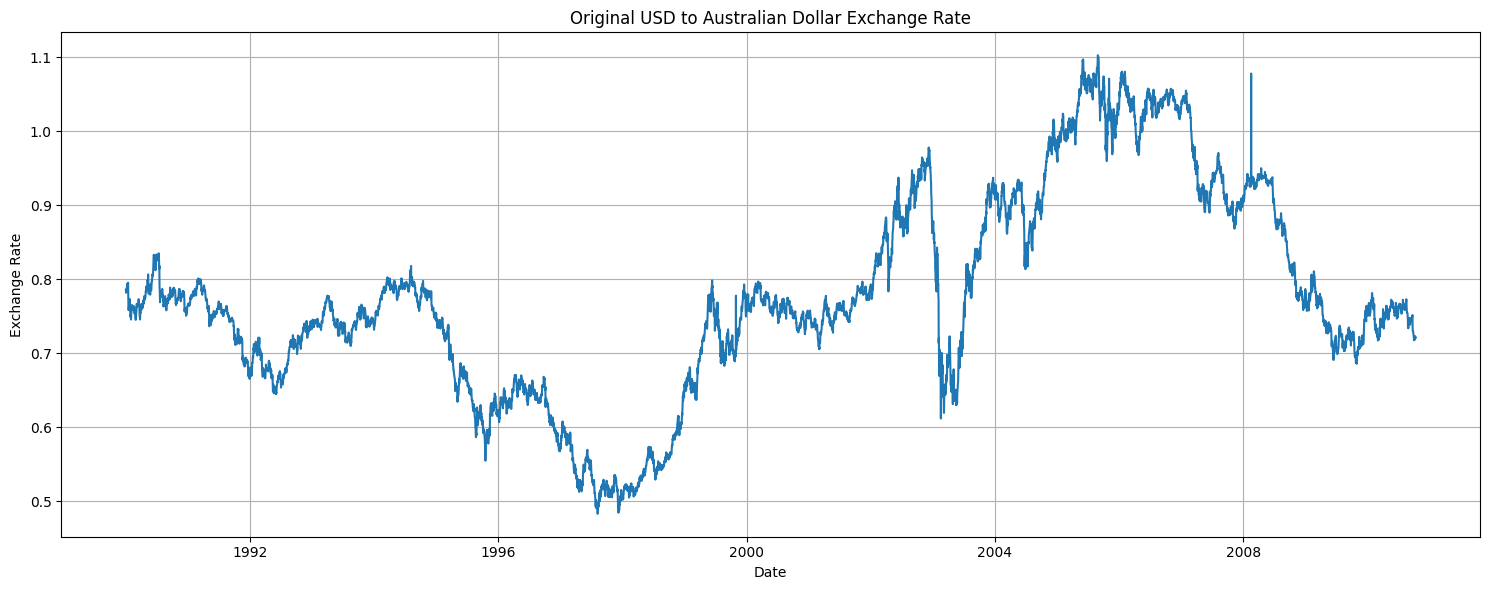

In [26]:
# Plot the original exchange-rate series
plt.figure(figsize=(15, 6))

plt.plot(series)

# Add title and axis labels
plt.title('Original USD to Australian Dollar Exchange Rate')
plt.xlabel('Date')
plt.ylabel('Exchange Rate')

# Add grid for easier interpretation
plt.grid(True)

plt.tight_layout()
plt.show()

In [27]:
# Apply first-order differencing
# Differencing subtracts the previous observation from the current observation
diff_series = series.diff().dropna()

# Display the first few differenced values
print(diff_series.head())

date
1990-01-02   -0.0037
1990-01-03    0.0049
1990-01-04   -0.0007
1990-01-05   -0.0011
1990-01-06    0.0017
Name: Ex_rate, dtype: float64


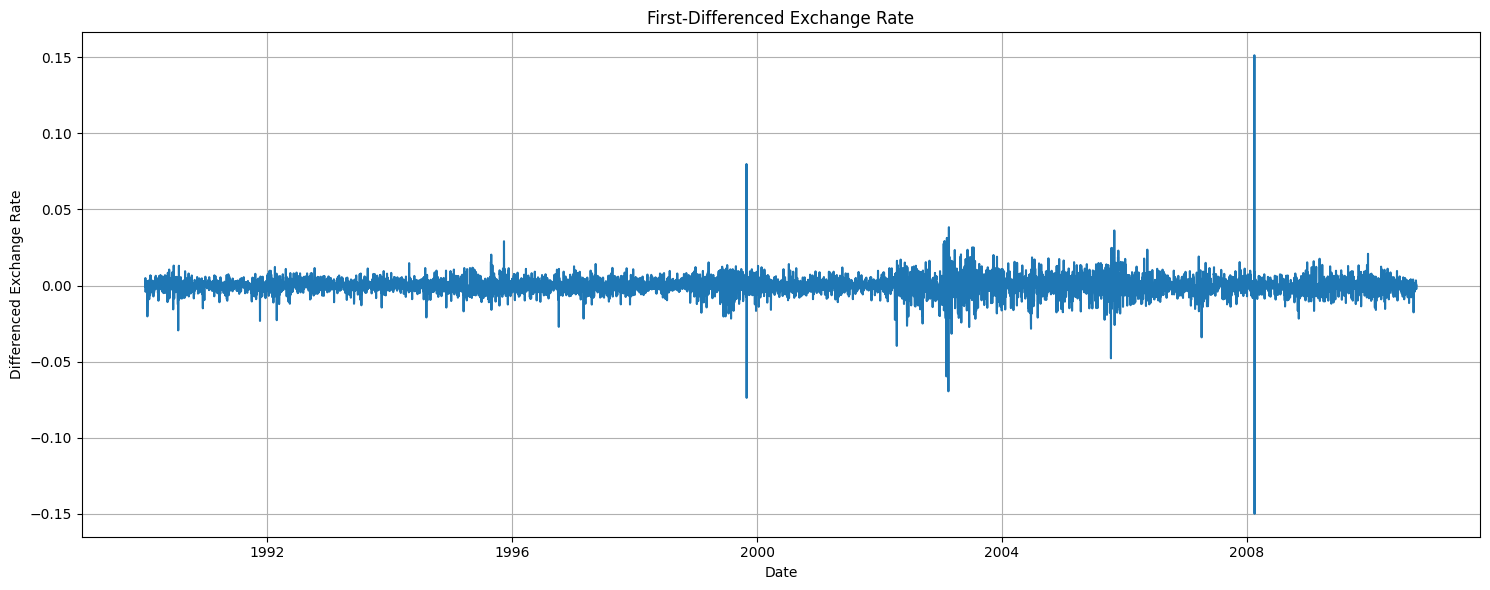

In [28]:
# Plot the first-differenced series
plt.figure(figsize=(15, 6))

plt.plot(diff_series)

# Add title and labels
plt.title('First-Differenced Exchange Rate')
plt.xlabel('Date')
plt.ylabel('Differenced Exchange Rate')

plt.grid(True)

plt.tight_layout()
plt.show()

In [29]:
# Perform ADF test on the differenced series
adf_diff_result = adfuller(diff_series)

# Extract test statistic and p-value
adf_diff_statistic = adf_diff_result[0]
adf_diff_p_value = adf_diff_result[1]

print("ADF Test Statistic after differencing:", adf_diff_statistic)
print("ADF p-value after differencing:", adf_diff_p_value)

ADF Test Statistic after differencing: -99.3934312011863
ADF p-value after differencing: 0.0


In [30]:
# Check whether the differenced series is stationary
if adf_diff_p_value < 0.05:
    print("\nThe differenced series is stationary.")
    print("Therefore, d = 1 can be used.")
else:
    print("\nThe differenced series is still non-stationary.")
    print("Additional differencing may be required.")


The differenced series is stationary.
Therefore, d = 1 can be used.


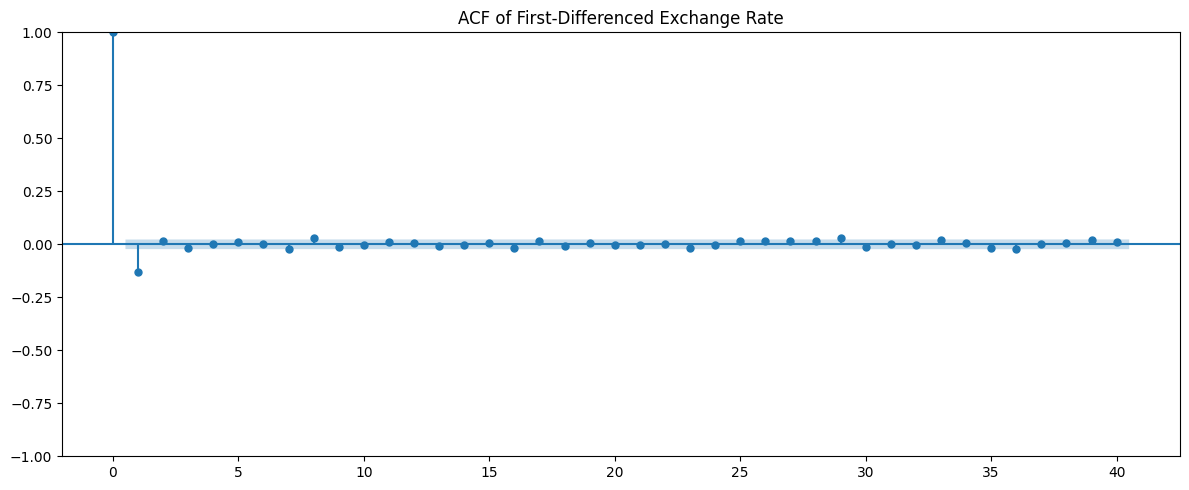

In [31]:
# Create a figure for the ACF plot
plt.figure(figsize=(12, 5))

# Plot the Autocorrelation Function
plot_acf(
    diff_series,
    lags=40,
    ax=plt.gca()
)

plt.title('ACF of First-Differenced Exchange Rate')
plt.tight_layout()
plt.show()

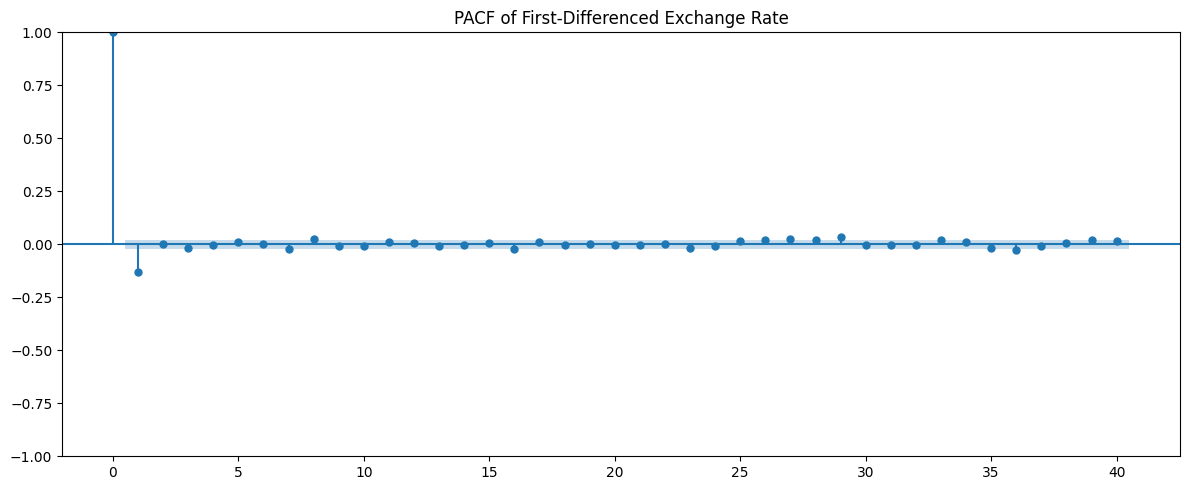

In [32]:
# Create a figure for the PACF plot
plt.figure(figsize=(12, 5))

# Plot the Partial Autocorrelation Function
plot_pacf(
    diff_series,
    lags=40,
    method='ywm',
    ax=plt.gca()
)

plt.title('PACF of First-Differenced Exchange Rate')
plt.tight_layout()
plt.show()

In [33]:
# Calculate the index corresponding to 80% of the observations
train_size = int(len(series) * 0.80)

# First 80% of observations are used for training
train = series.iloc[:train_size]

# Remaining 20% are used for testing
test = series.iloc[train_size:]

# Display the sizes
print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 6070
Testing observations: 1518

Training period:
1990-01-01 00:00:00 to 2006-08-14 00:00:00

Testing period:
2006-08-15 00:00:00 to 2010-10-10 00:00:00


In [34]:
# Create the ARIMA(1,1,1) model
arima_model = ARIMA(
    train,
    order=(1, 1, 1)
)

# Fit the model to the training data
arima_result = arima_model.fit()

# Display the model summary
print(arima_result.summary())

C:\Users\BALAJI\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\BALAJI\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\BALAJI\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                Ex_rate   No. Observations:                 6070
Model:                 ARIMA(1, 1, 1)   Log Likelihood               22719.046
Date:                Fri, 18 Sep 2026   AIC                         -45432.092
Time:                        16:13:06   BIC                         -45411.959
Sample:                    01-01-1990   HQIC                        -45425.104
                         - 08-14-2006                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5972      0.062     -9.648      0.000      -0.719      -0.476
ma.L1          0.5398      0.064      8.430      0.000       0.414       0.665
sigma2      3.281e-05   1.95e-07    168.198      0.0

In [35]:
# Display the Akaike Information Criterion
print("AIC:", arima_result.aic)

# Display the Bayesian Information Criterion
print("BIC:", arima_result.bic)

AIC: -45432.09158294726
BIC: -45411.95873556975


In [36]:
# Extract residuals from the fitted ARIMA model
residuals = arima_result.resid

# Display the first few residual values
print(residuals.head())

date
1990-01-01    0.785500
1990-01-02   -0.003700
1990-01-03    0.004677
1990-01-04   -0.000295
1990-01-05   -0.001359
dtype: float64


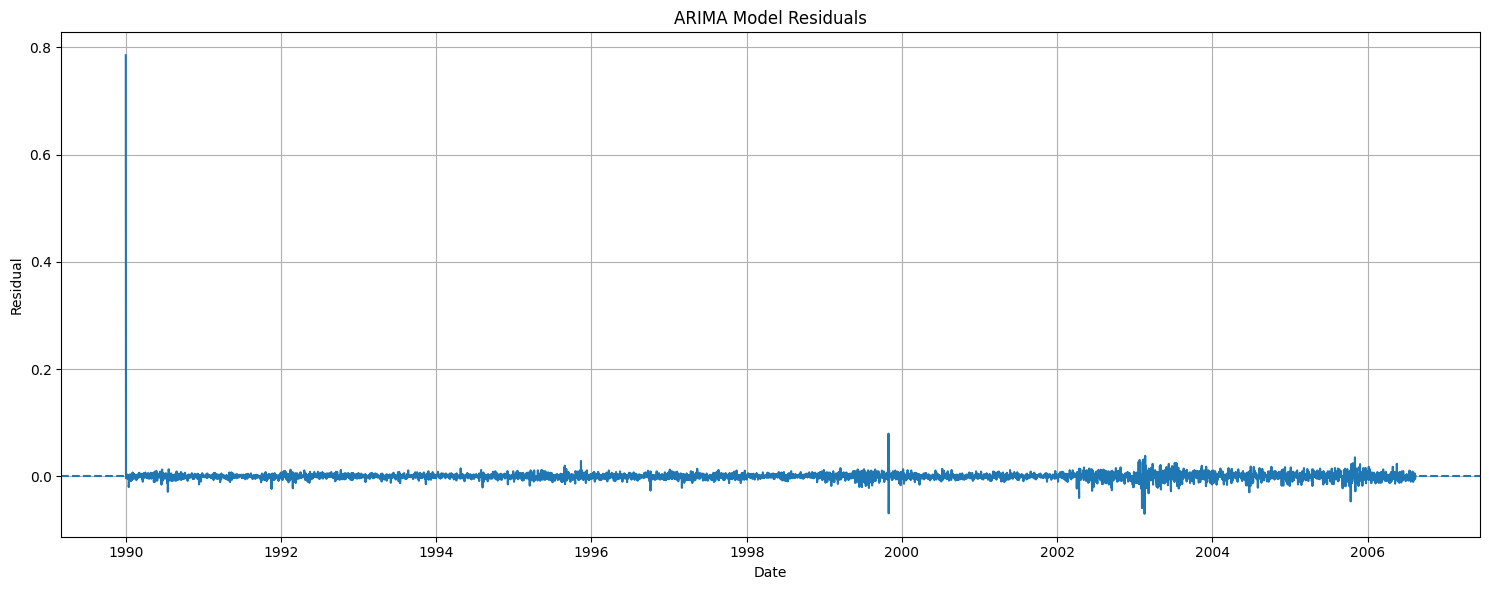

In [37]:
# Plot the residuals over time
plt.figure(figsize=(15, 6))

plt.plot(residuals)

plt.title('ARIMA Model Residuals')
plt.xlabel('Date')
plt.ylabel('Residual')

plt.axhline(
    y=0,
    linestyle='--'
)

plt.grid(True)

plt.tight_layout()
plt.show()

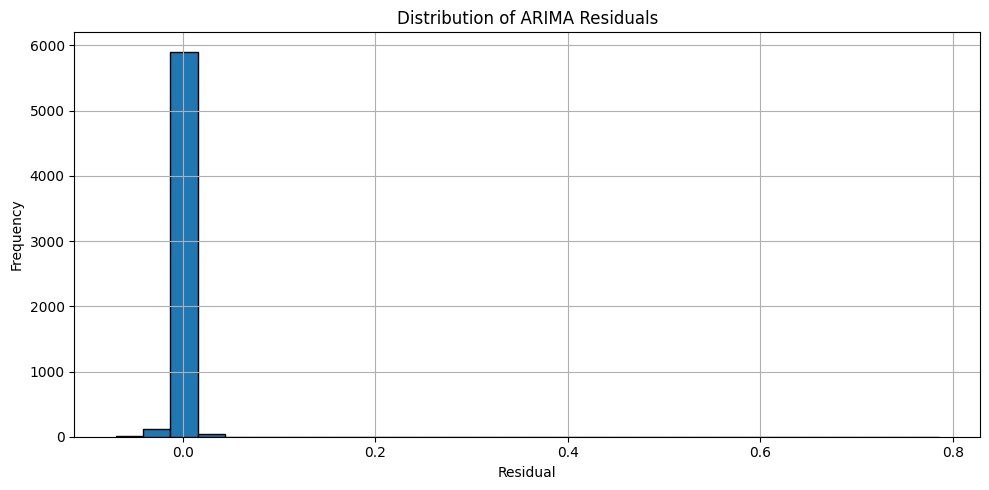

In [38]:
# Create a histogram of the ARIMA residuals
plt.figure(figsize=(10, 5))

plt.hist(
    residuals,
    bins=30,
    edgecolor='black'
)

plt.title('Distribution of ARIMA Residuals')
plt.xlabel('Residual')
plt.ylabel('Frequency')

plt.grid(True)

plt.tight_layout()
plt.show()

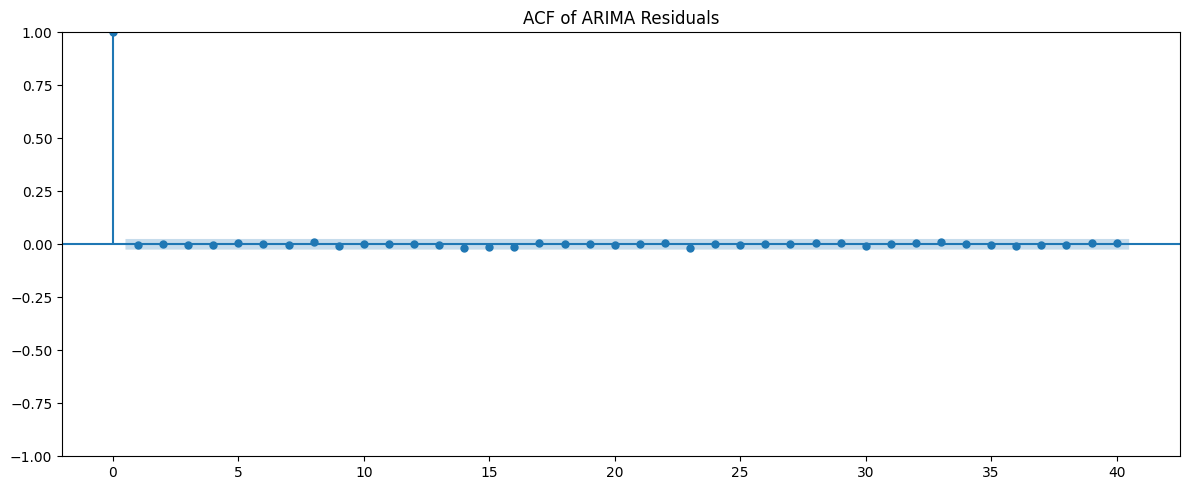

In [39]:
# Plot the ACF of the residuals
plt.figure(figsize=(12, 5))

plot_acf(
    residuals.dropna(),
    lags=40,
    ax=plt.gca()
)

plt.title('ACF of ARIMA Residuals')

plt.tight_layout()
plt.show()

In [40]:
# Perform the Ljung-Box test on the ARIMA residuals
ljung_box_result = acorr_ljungbox(
    residuals.dropna(),
    lags=[10, 20],
    return_df=True
)

# Display the test results
print(ljung_box_result)

     lb_stat  lb_pvalue
10  1.647217   0.998399
20  5.913127   0.999010


In [41]:
# Display the p-values from the Ljung-Box test
print("\nLjung-Box p-values:")
print(ljung_box_result['lb_pvalue'])


Ljung-Box p-values:
10    0.998399
20    0.999010
Name: lb_pvalue, dtype: float64


In [42]:
# Display the p-values from the Ljung-Box test
print("\nLjung-Box p-values:")
print(ljung_box_result['lb_pvalue'])


Ljung-Box p-values:
10    0.998399
20    0.999010
Name: lb_pvalue, dtype: float64


In [43]:
# Generate forecasts for exactly the same number of observations
# as contained in the test dataset
forecast_result = arima_result.get_forecast(
    steps=len(test)
)

# Extract the predicted mean values
forecast = forecast_result.predicted_mean

# Make sure the forecast uses the same index as the test data
forecast.index = test.index

# Display the first few forecast values
print(forecast.head())

date
2006-08-15    1.023685
2006-08-16    1.023606
2006-08-17    1.023653
2006-08-18    1.023625
2006-08-19    1.023642
Name: predicted_mean, dtype: float64


In [44]:
# Calculate confidence intervals for the forecasts
forecast_conf_int = forecast_result.conf_int()

# Assign the test dates to the confidence interval index
forecast_conf_int.index = test.index

# Display the first few confidence intervals
print(forecast_conf_int.head())

            lower Ex_rate  upper Ex_rate
date                                    
2006-08-15       1.012459       1.034912
2006-08-16       1.008179       1.039033
2006-08-17       1.004726       1.042581
2006-08-18       1.001864       1.045386
2006-08-19       0.999315       1.047969


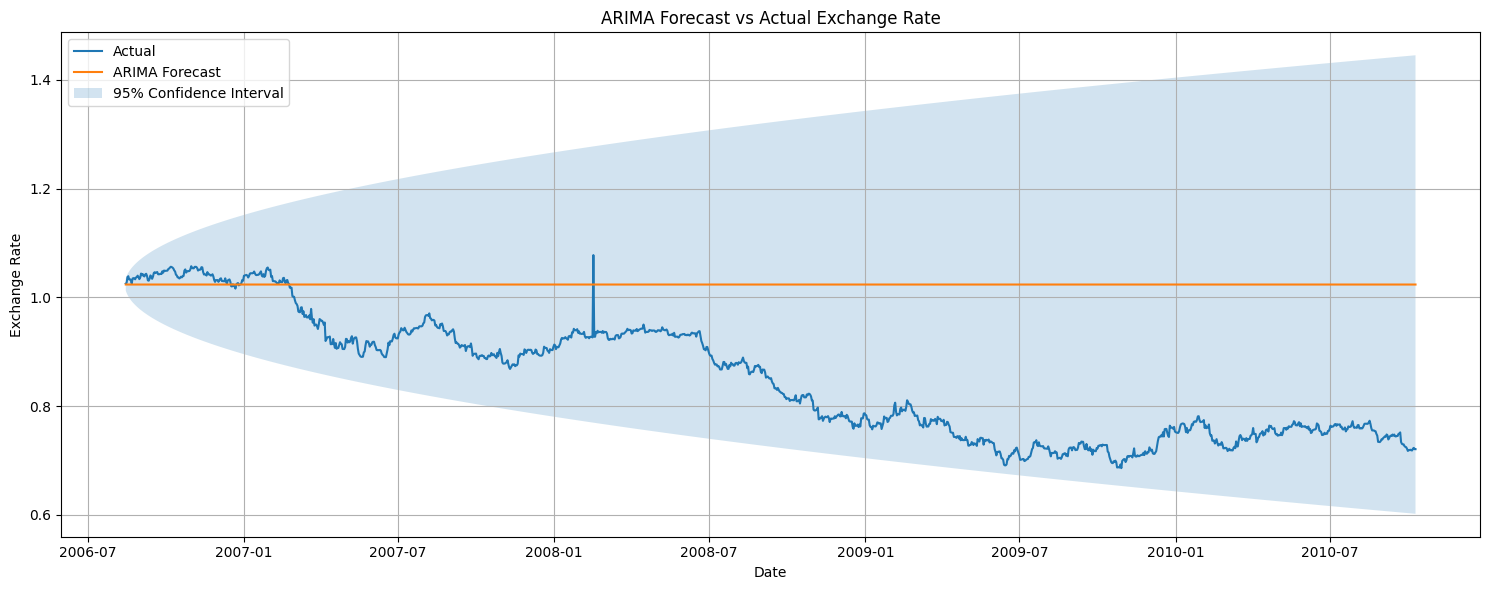

In [45]:
# Create a plot for the actual and predicted exchange rates
plt.figure(figsize=(15, 6))

# Plot the actual test observations
plt.plot(
    test.index,
    test,
    label='Actual',
    linewidth=1.5
)

# Plot ARIMA predictions
plt.plot(
    forecast.index,
    forecast,
    label='ARIMA Forecast',
    linewidth=1.5
)

# Add confidence interval
plt.fill_between(
    forecast_conf_int.index,
    forecast_conf_int.iloc[:, 0],
    forecast_conf_int.iloc[:, 1],
    alpha=0.2,
    label='95% Confidence Interval'
)

# Add title and labels
plt.title('ARIMA Forecast vs Actual Exchange Rate')
plt.xlabel('Date')
plt.ylabel('Exchange Rate')

# Display legend
plt.legend()

# Add grid
plt.grid(True)

plt.tight_layout()
plt.show()

In [46]:
# Calculate Mean Absolute Error
mae_arima = mean_absolute_error(
    test,
    forecast
)

# Calculate Root Mean Squared Error
rmse_arima = np.sqrt(
    mean_squared_error(test, forecast)
)

# Calculate Mean Absolute Percentage Error
# We use a small epsilon to avoid division by zero
epsilon = 1e-10

mape_arima = np.mean(
    np.abs(
        (test - forecast) /
        np.maximum(np.abs(test), epsilon)
    )
) * 100

# Display the error metrics
print("ARIMA Performance")
print("-----------------")
print("MAE  :", mae_arima)
print("RMSE :", rmse_arima)
print("MAPE :", mape_arima, "%")

ARIMA Performance
-----------------
MAE  : 0.17770970449121345
RMSE : 0.2054366965966928
MAPE : 22.797966173811552 %


In [47]:
# Define several candidate ARIMA parameter combinations
# We keep d = 1 because first-order differencing was used
candidate_orders = [
    (1, 1, 0),
    (0, 1, 1),
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2)
]

# Create an empty list to store model results
arima_comparison = []

# Fit every candidate model
for order in candidate_orders:
    
    try:
        # Create the ARIMA model
        model = ARIMA(
            train,
            order=order
        )
        
        # Fit the model
        result = model.fit()
        
        # Store order, AIC and BIC
        arima_comparison.append({
            'Order': order,
            'AIC': result.aic,
            'BIC': result.bic
        })
        
    except Exception as e:
        # If a particular model fails, display the error
        print(f"Model {order} failed: {e}")

# Convert results into a DataFrame
arima_comparison_df = pd.DataFrame(arima_comparison)

# Sort models by AIC
arima_comparison_df = arima_comparison_df.sort_values(
    by='AIC'
)

# Display comparison
arima_comparison_df

C:\Users\BALAJI\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\BALAJI\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\BALAJI\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\BALAJI\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\BALAJI\AppData\Local\Programs\Python\Python310\

,Order,AIC,BIC
2,"(1, 1, 1)",-45432.091583,-45411.958736
4,"(1, 1, 2)",-45429.880419,-45403.036622
5,"(2, 1, 2)",-45428.425715,-45394.870969
0,"(1, 1, 0)",-45425.956729,-45412.534831
1,"(0, 1, 1)",-45424.939922,-45411.518024
3,"(2, 1, 1)",-45400.257795,-45373.413999


# Evaluation and Comparison

In [48]:
# Import Exponential Smoothing from statsmodels
# This model gives more importance to recent observations
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [49]:
# Create the Exponential Smoothing model
#
# trend='add' means that the model allows the exchange rate
# to have an additive trend over time.
#
# seasonal=None means that we are not assuming a fixed
# repeating seasonal pattern.
#
# damped_trend=True reduces the effect of the trend as we
# move further into the future.
es_model = ExponentialSmoothing(
    train,
    trend='add',
    seasonal=None,
    damped_trend=True
)

# Fit the model using the training data
es_result = es_model.fit(
    optimized=True
)

# Display the model summary
print(es_result.summary())

C:\Users\BALAJI\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                       ExponentialSmoothing Model Results                       
Dep. Variable:                  Ex_rate   No. Observations:                 6070
Model:             ExponentialSmoothing   SSE                              0.199
Optimized:                         True   AIC                         -62654.072
Trend:                         Additive   BIC                         -62620.516
Seasonal:                          None   AICC                        -62654.053
Seasonal Periods:                  None   Date:                 Fri, 18 Sep 2026
Box-Cox:                          False   Time:                         16:16:37
Box-Cox Coeff.:                    None                                         
                       coeff                 code              optimized      
------------------------------------------------------------------------------
smoothing_level            0.9411398                alpha                 True
smoothing_trend            0.00182

In [50]:
# Generate forecasts for the complete testing period
# len(test) ensures that both models predict the same number
# of future observations.
es_forecast = es_result.forecast(
    steps=len(test)
)

# Make sure the forecast has the same date index as the test data
es_forecast.index = test.index

# Display the first five predictions
print(es_forecast.head())

date
2006-08-15    1.023522
2006-08-16    1.023505
2006-08-17    1.023489
2006-08-18    1.023473
2006-08-19    1.023458
dtype: float64


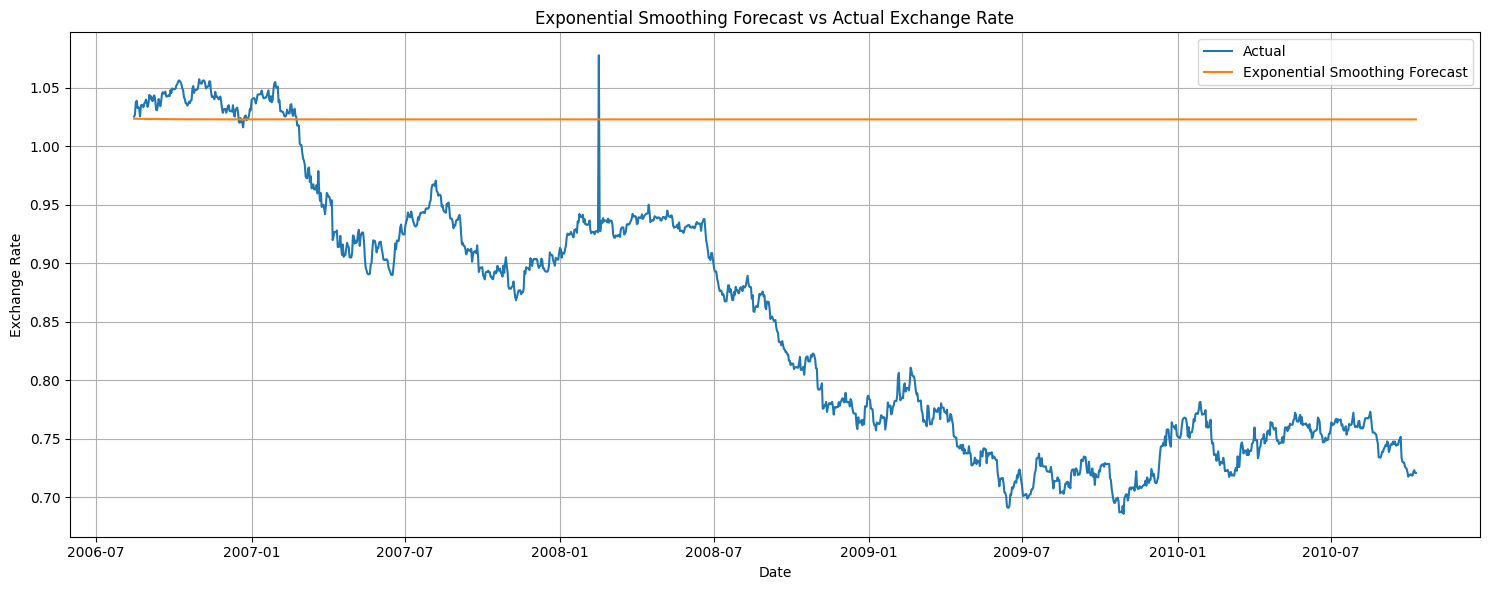

In [53]:
# Create a figure for comparing actual values with
# Exponential Smoothing predictions
plt.figure(figsize=(15, 6))

# Plot actual exchange rates from the testing dataset
plt.plot(
    test.index,
    test,
    label='Actual',
    linewidth=1.5
)

# Plot Exponential Smoothing predictions
plt.plot(
    es_forecast.index,
    es_forecast,
    label='Exponential Smoothing Forecast',
    linewidth=1.5
)

# Add title and axis labels
plt.title('Exponential Smoothing Forecast vs Actual Exchange Rate')
plt.xlabel('Date')
plt.ylabel('Exchange Rate')

# Display legend
plt.legend()

# Add grid
plt.grid(True)

plt.tight_layout()
plt.show()

In [54]:
# Calculate Mean Absolute Error for Exponential Smoothing
mae_es = mean_absolute_error(
    test,
    es_forecast
)

print("Exponential Smoothing MAE:", mae_es)

Exponential Smoothing MAE: 0.17717988191037776


In [55]:
# Calculate Mean Squared Error first
mse_es = mean_squared_error(
    test,
    es_forecast
)

# Take the square root to obtain RMSE
rmse_es = np.sqrt(mse_es)

print("Exponential Smoothing RMSE:", rmse_es)

Exponential Smoothing RMSE: 0.20485529526269378


In [56]:
# A very small value is used to prevent division by zero
# in case an actual value is zero.
epsilon = 1e-10

# Calculate MAPE
mape_es = np.mean(
    np.abs(
        (test - es_forecast) /
        np.maximum(np.abs(test), epsilon)
    )
) * 100

print("Exponential Smoothing MAPE:", mape_es, "%")

Exponential Smoothing MAPE: 22.73092624834939 %


In [57]:
# Create a DataFrame containing the performance metrics
# for both forecasting models.
comparison = pd.DataFrame({
    'Model': [
        'ARIMA',
        'Exponential Smoothing'
    ],
    
    'MAE': [
        mae_arima,
        mae_es
    ],
    
    'RMSE': [
        rmse_arima,
        rmse_es
    ],
    
    'MAPE (%)': [
        mape_arima,
        mape_es
    ]
})

# Display the comparison table
comparison

,Model,MAE,RMSE,MAPE (%)
0,ARIMA,0.17771,0.205437,22.797966
1,Exponential Smoothing,0.17718,0.204855,22.730926


In [58]:
# Create a copy of the comparison table
# so that we can format the numbers without changing
# the original metric values.
comparison_display = comparison.copy()

# Round MAE and RMSE to 6 decimal places
comparison_display['MAE'] = comparison_display['MAE'].round(6)
comparison_display['RMSE'] = comparison_display['RMSE'].round(6)

# Round MAPE to 3 decimal places
comparison_display['MAPE (%)'] = comparison_display['MAPE (%)'].round(3)

# Display the formatted table
comparison_display

,Model,MAE,RMSE,MAPE (%)
0,ARIMA,0.17771,0.205437,22.798
1,Exponential Smoothing,0.17718,0.204855,22.731


In [59]:
# Find the model with the smallest MAE
best_mae_model = comparison.loc[
    comparison['MAE'].idxmin(),
    'Model'
]

print("Model with lower MAE:", best_mae_model)

Model with lower MAE: Exponential Smoothing


In [60]:
# Find the model with the smallest RMSE
best_rmse_model = comparison.loc[
    comparison['RMSE'].idxmin(),
    'Model'
]

print("Model with lower RMSE:", best_rmse_model)

Model with lower RMSE: Exponential Smoothing


In [61]:
# Find the model with the smallest MAPE
best_mape_model = comparison.loc[
    comparison['MAPE (%)'].idxmin(),
    'Model'
]

print("Model with lower MAPE:", best_mape_model)

Model with lower MAPE: Exponential Smoothing


In [62]:
# Count how many metrics are lower for each model
arima_wins = 0
es_wins = 0

# Compare MAE
if mae_arima < mae_es:
    arima_wins += 1
else:
    es_wins += 1

# Compare RMSE
if rmse_arima < rmse_es:
    arima_wins += 1
else:
    es_wins += 1

# Compare MAPE
if mape_arima < mape_es:
    arima_wins += 1
else:
    es_wins += 1

# Display the counts
print("ARIMA lower-error metrics:", arima_wins)
print("Exponential Smoothing lower-error metrics:", es_wins)

ARIMA lower-error metrics: 0
Exponential Smoothing lower-error metrics: 3


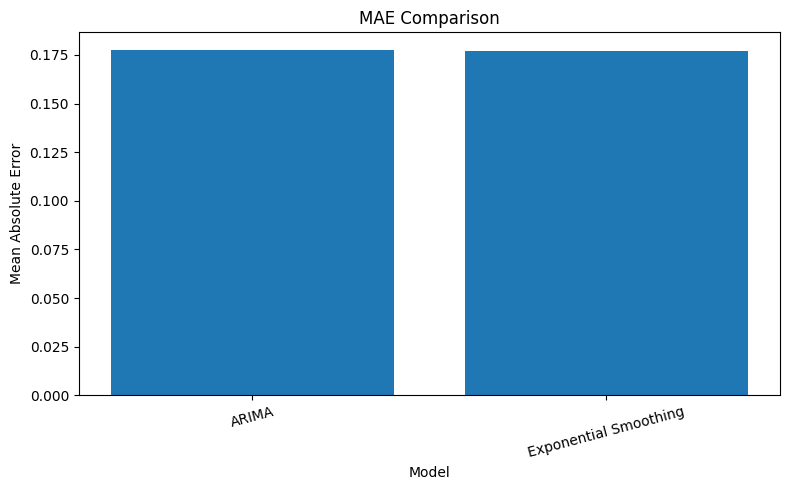

In [63]:
# Plot MAE for both models
plt.figure(figsize=(8, 5))

plt.bar(
    comparison['Model'],
    comparison['MAE']
)

plt.title('MAE Comparison')
plt.xlabel('Model')
plt.ylabel('Mean Absolute Error')

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

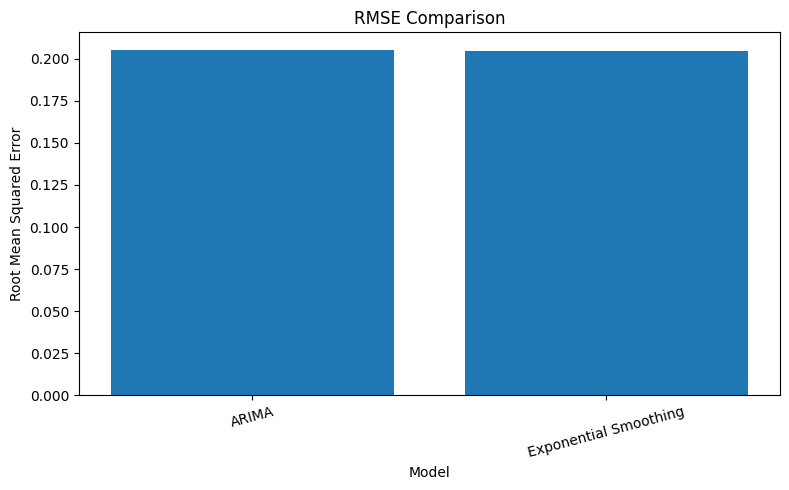

In [64]:
# Plot RMSE for both models
plt.figure(figsize=(8, 5))

plt.bar(
    comparison['Model'],
    comparison['RMSE']
)

plt.title('RMSE Comparison')
plt.xlabel('Model')
plt.ylabel('Root Mean Squared Error')

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

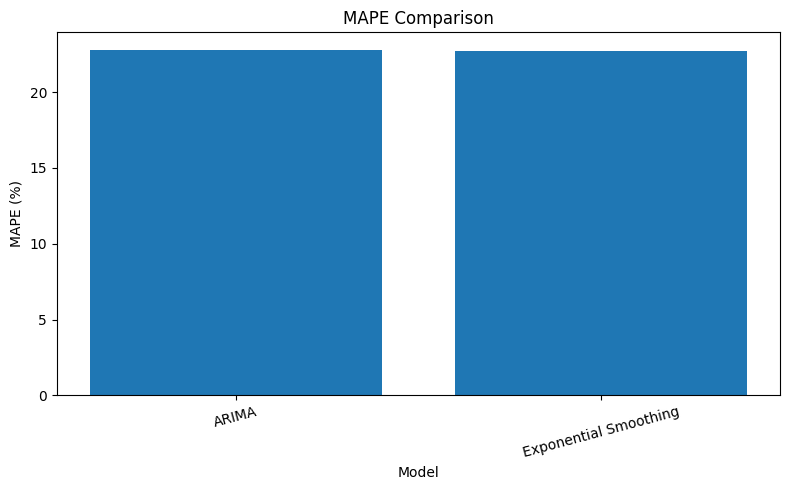

In [65]:
# Plot MAPE for both models
plt.figure(figsize=(8, 5))

plt.bar(
    comparison['Model'],
    comparison['MAPE (%)']
)

plt.title('MAPE Comparison')
plt.xlabel('Model')
plt.ylabel('MAPE (%)')

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

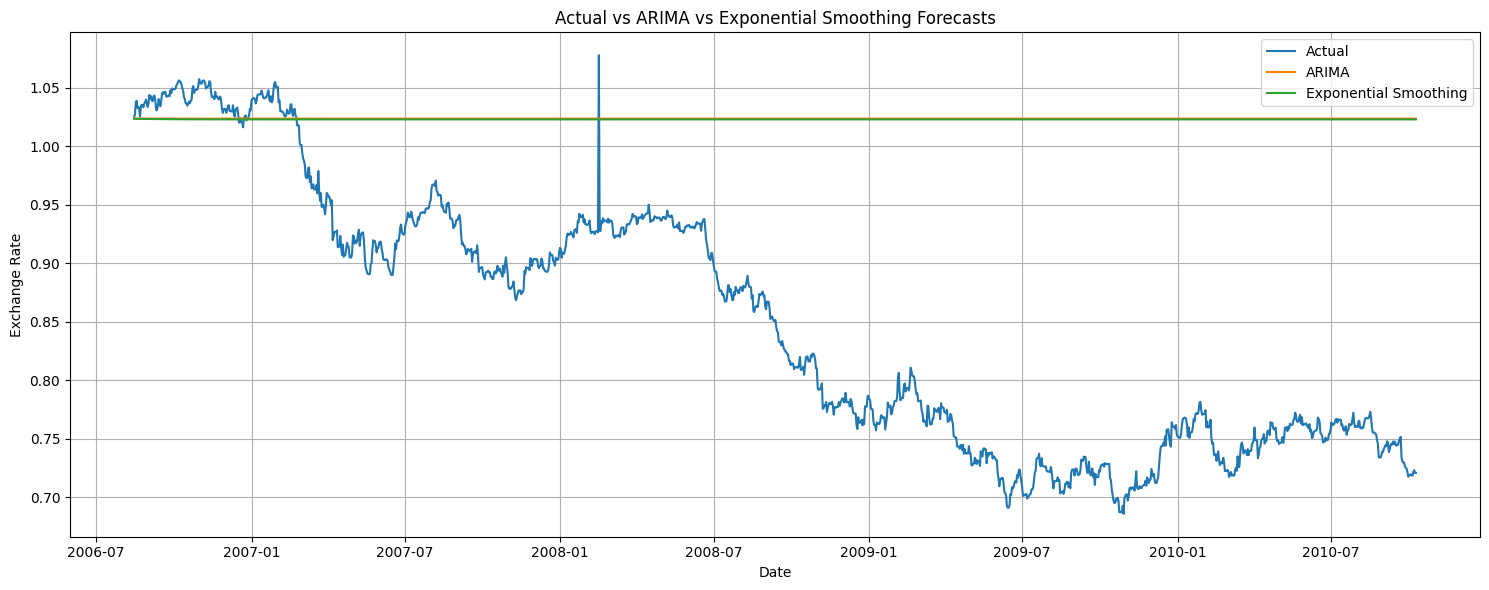

In [66]:
# Create a figure for comparing all three series
plt.figure(figsize=(15, 6))

# Plot the actual exchange rates
plt.plot(
    test.index,
    test,
    label='Actual',
    linewidth=1.5
)

# Plot ARIMA predictions
plt.plot(
    forecast.index,
    forecast,
    label='ARIMA',
    linewidth=1.5
)

# Plot Exponential Smoothing predictions
plt.plot(
    es_forecast.index,
    es_forecast,
    label='Exponential Smoothing',
    linewidth=1.5
)

# Add title and labels
plt.title('Actual vs ARIMA vs Exponential Smoothing Forecasts')
plt.xlabel('Date')
plt.ylabel('Exchange Rate')

# Display the legend
plt.legend()

# Add grid
plt.grid(True)

plt.tight_layout()
plt.show()

In [67]:
# Calculate the error for ARIMA
# Positive value means actual > forecast
arima_errors = test - forecast

# Calculate the error for Exponential Smoothing
es_errors = test - es_forecast

# Display basic statistics of the errors
print("ARIMA Error Statistics:")
print(arima_errors.describe())

print("\nExponential Smoothing Error Statistics:")
print(es_errors.describe())

ARIMA Error Statistics:
count    1518.000000
mean       -0.173670
std         0.109776
min        -0.337741
25%        -0.272632
50%        -0.172898
75%        -0.090114
max         0.054124
dtype: float64

Exponential Smoothing Error Statistics:
count    1518.000000
mean       -0.172996
std         0.109754
min        -0.337054
25%        -0.271945
50%        -0.172211
75%        -0.089427
max         0.054811
dtype: float64


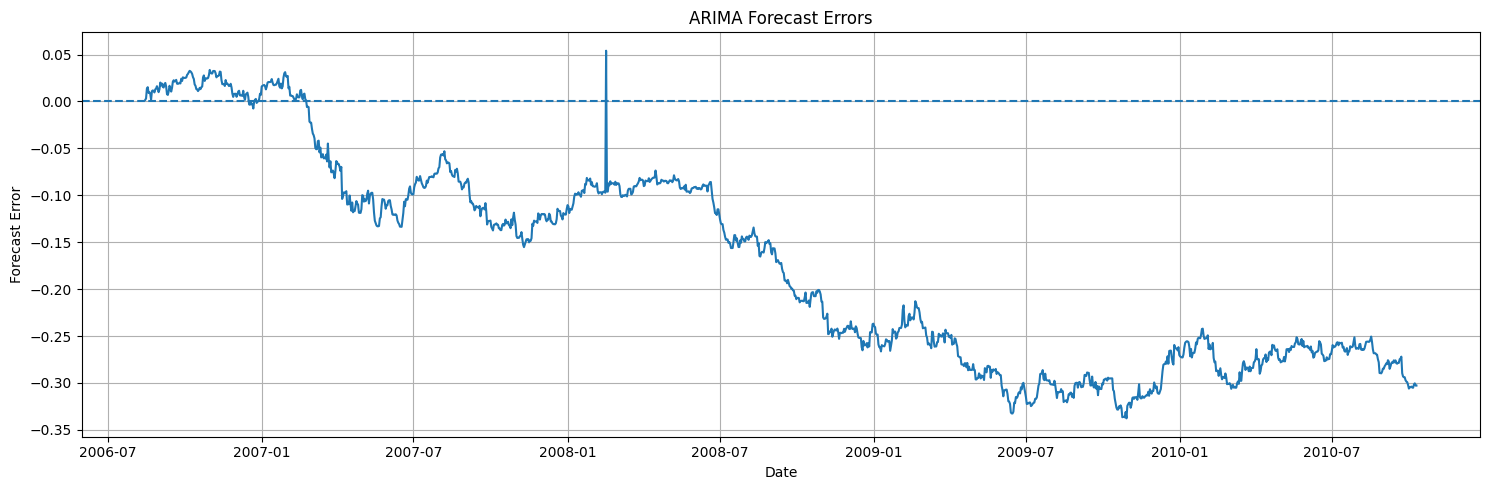

In [68]:
# Plot ARIMA forecast errors
plt.figure(figsize=(15, 5))

plt.plot(
    arima_errors.index,
    arima_errors
)

# A horizontal zero line helps identify positive and negative errors
plt.axhline(
    y=0,
    linestyle='--'
)

plt.title('ARIMA Forecast Errors')
plt.xlabel('Date')
plt.ylabel('Forecast Error')

plt.grid(True)

plt.tight_layout()
plt.show()

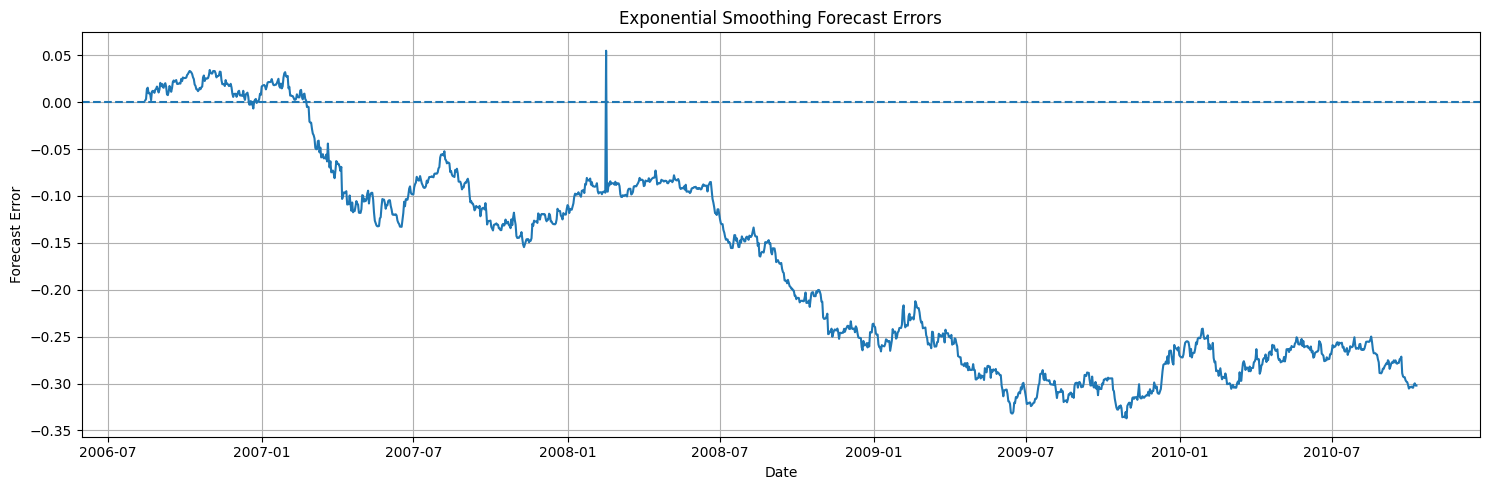

In [69]:
# Plot Exponential Smoothing forecast errors
plt.figure(figsize=(15, 5))

plt.plot(
    es_errors.index,
    es_errors
)

# Add zero reference line
plt.axhline(
    y=0,
    linestyle='--'
)

plt.title('Exponential Smoothing Forecast Errors')
plt.xlabel('Date')
plt.ylabel('Forecast Error')

plt.grid(True)

plt.tight_layout()
plt.show()

In [70]:
# Print all three metrics for both models
print("========== MODEL COMPARISON ==========")

print("\nARIMA")
print("MAE  :", round(mae_arima, 6))
print("RMSE :", round(rmse_arima, 6))
print("MAPE :", round(mape_arima, 3), "%")

print("\nExponential Smoothing")
print("MAE  :", round(mae_es, 6))
print("RMSE :", round(rmse_es, 6))
print("MAPE :", round(mape_es, 3), "%")

print("\n========== LOWER ERROR MODEL ==========")

print("Lower MAE  :", best_mae_model)
print("Lower RMSE :", best_rmse_model)
print("Lower MAPE :", best_mape_model)

========== MODEL COMPARISON ==========

ARIMA
MAE  : 0.17771
RMSE : 0.205437
MAPE : 22.798 %

Exponential Smoothing
MAE  : 0.17718
RMSE : 0.204855
MAPE : 22.731 %

========== LOWER ERROR MODEL ==========
Lower MAE  : Exponential Smoothing
Lower RMSE : Exponential Smoothing
Lower MAPE : Exponential Smoothing


#### Model comparison
ARIMA and Exponential Smoothing were evaluated using MAE, RMSE, and MAPE on the same 20% chronological test dataset. ARIMA obtained an MAE of  RMSE  , and MAPE . Exponential Smoothing obtained an MAE , RMSE , and MAPE . Since lower values indicate smaller forecasting errors, the metrics were used to compare the predictive performance of the two models. The actual-versus-forecast plots were also examined to determine how closely each model followed the observed exchange-rate movements.

#### conclusion
ARIMA and Exponential Smoothing were applied to historical USD to Australian Dollar exchange-rate data. The dataset was chronologically divided into training and testing sets, ensuring that future observations were not used during model training. ARIMA was developed after examining stationarity, differencing, ACF, and PACF, while Exponential Smoothing was implemented using an additive damped trend.

ARIMA has the advantage of explicitly modeling autocorrelation and can be useful when temporal dependencies are important. Exponential Smoothing is simpler and gives greater importance to recent observations, making it computationally efficient and useful for capturing level and trend. However, neither approach can guarantee accurate predictions during unexpected market movements or structural changes.

Overall, the model with the lower test-set error metrics can be considered the better-performing model for this particular dataset and forecasting period. Further improvements could be achieved by tuning ARIMA parameters, testing alternative Exponential Smoothing configurations, incorporating additional economic variables, and using rolling or walk-forward validation.